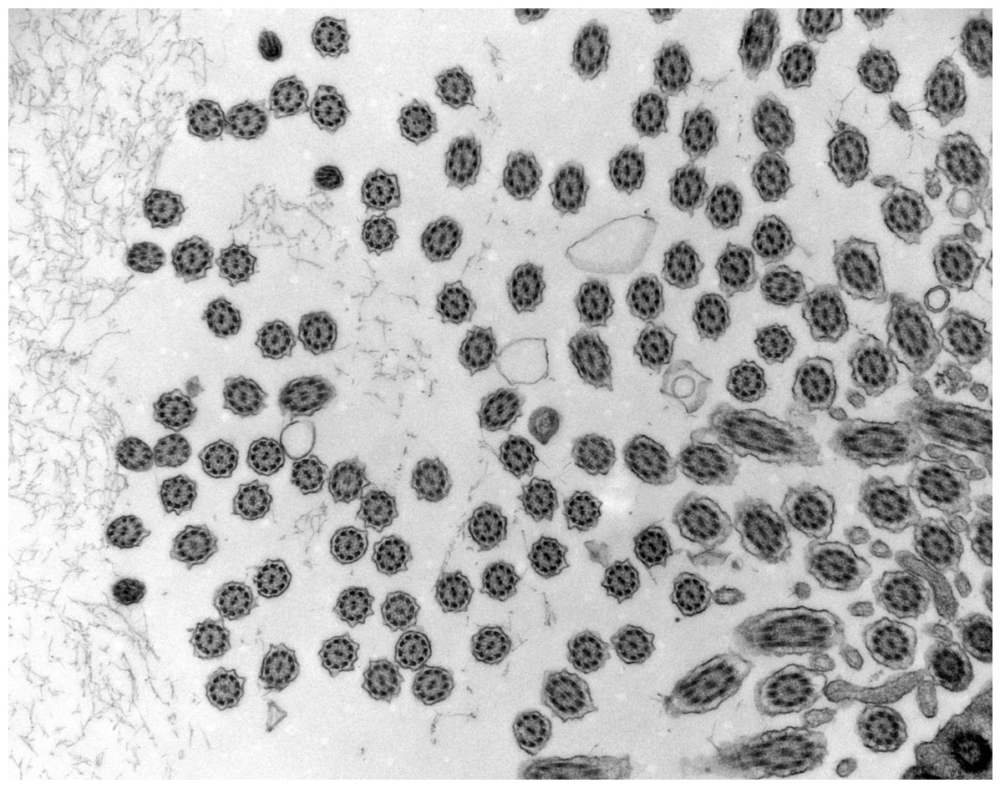

In [1]:
from utils import *

image_dir = Path.cwd().resolve().parent / "Data"
images = read_directory_gray(image_dir)
iu.plot_images(images[0])

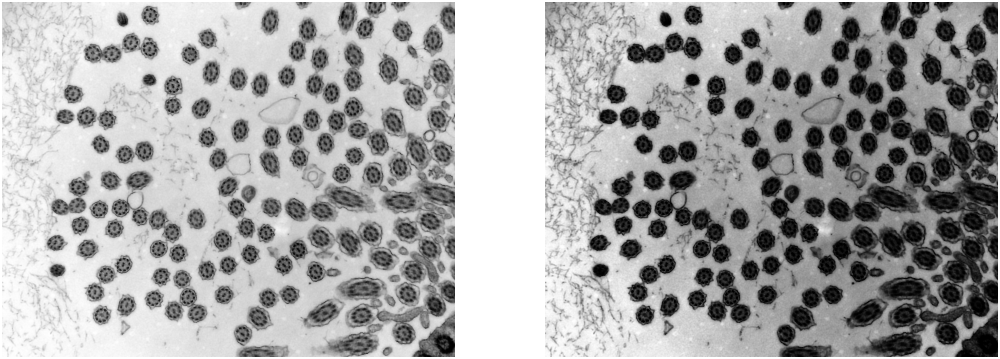

In [2]:
gamma = 2.5
blurred_imgs = [cv.bilateralFilter(img, 15, 75, 100, cv.BORDER_REFLECT) for img in images]
power_imgs = [pwr_image(blurred, gamma) for blurred in blurred_imgs]
iu.plot_images(blurred_imgs[0], power_imgs[0])

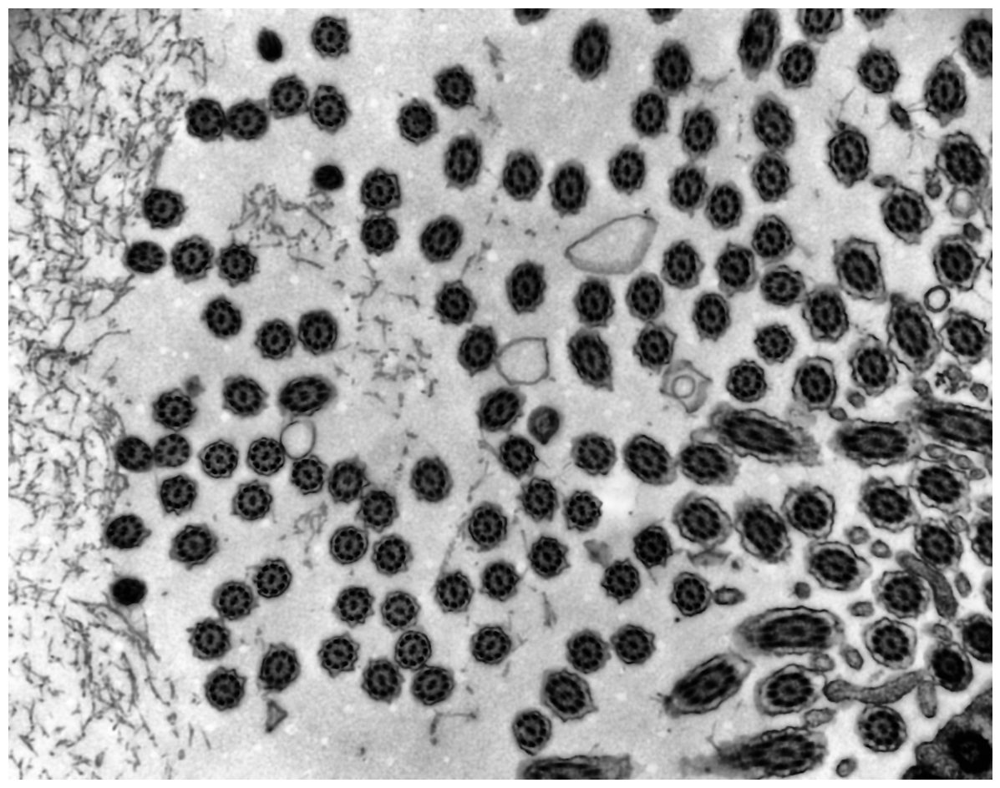

In [3]:
# clipLimit
# Threshold for contrast limiting.
# Higher -> more contrast
# Lower -> less contrast

# tileGridSize
# Size of grid for histogram equalization. 
# Input image will be divided into equally sized rectangular tiles.
# Lower -> more details
# Higher -> less details
clahe = cv.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_images = [clahe.apply(img) for img in power_imgs]
iu.plot_images(clahe_images[0])

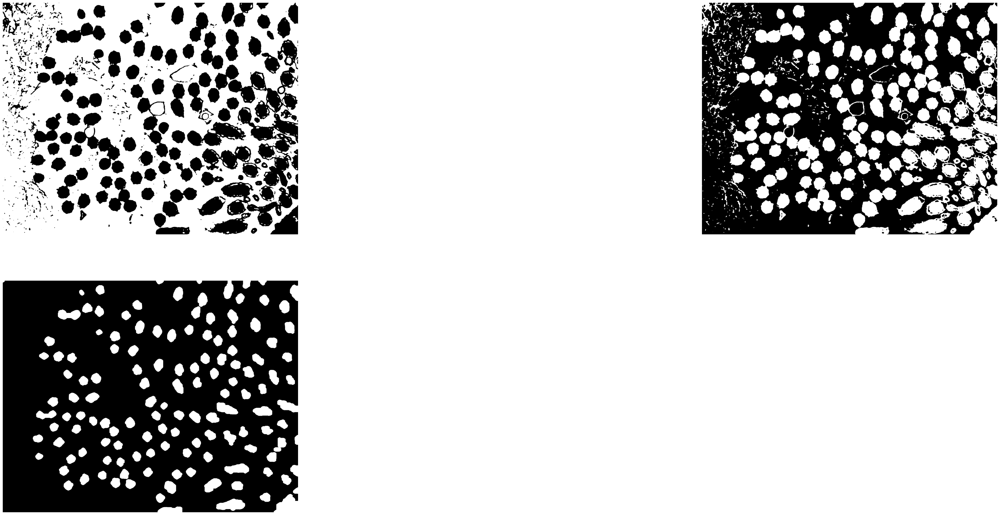

In [4]:
segmented_imgs = [otsu_threshold(clahe_image) for clahe_image in clahe_images]
inverted_segmented_imgs = [negate(segmented_img) for segmented_img in segmented_imgs]

opened_imgs = [morph_open(
    inverted_segmented_imgs, ker_erode_SE=False, ker_size_erode=6, iter_erode=12, ker_dilate_SE=True, ker_size_dilate=7, iter_dilate=7) for inverted_segmented_imgs in inverted_segmented_imgs]

iu.plot_images(
    segmented_imgs[0], inverted_segmented_imgs[0], opened_imgs[0])

# iu.save_image(inverted_segmented_imgs[0], image_dir / "mask.png")
# iu.save_image(opened_imgs[0], image_dir / "img.png")

Number of contours found: 105


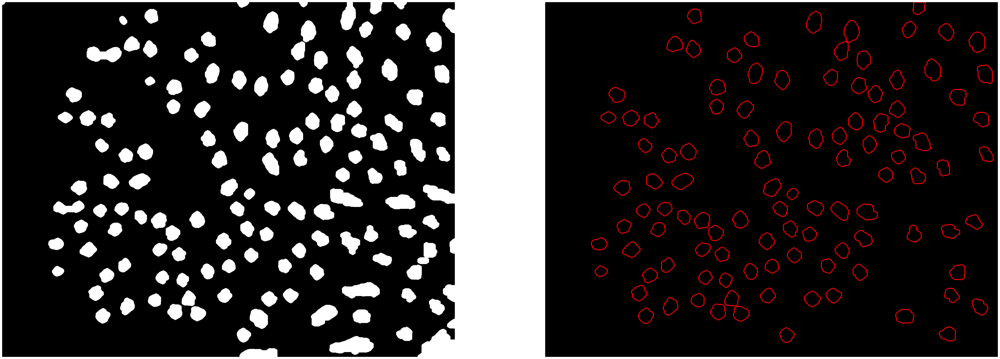

In [5]:
min_area = 5000
max_area = 15000

contours_in_imgs = [find_contours(opened_img) for opened_img in opened_imgs]
contours_in_imgs_filtered = []
for contours in contours_in_imgs:
    contours_in_imgs_filtered.append(
        [
            c
            for c in contours
            if cv.contourArea(c) > min_area and cv.contourArea(c) < max_area and 1.45 > height_width_ratio(c) > 0.55 and circularity(c) > 0.75
        ]
    )

rgb_img = cv.cvtColor(opened_imgs[0], cv.COLOR_GRAY2BGR)
drawn_contours = [draw_contours(rgb_img, contours, False) for contours in contours_in_imgs_filtered]

print(f"Number of contours found: {len(contours_in_imgs_filtered[0])}")
iu.plot_images(
    rgb_img, drawn_contours[0])

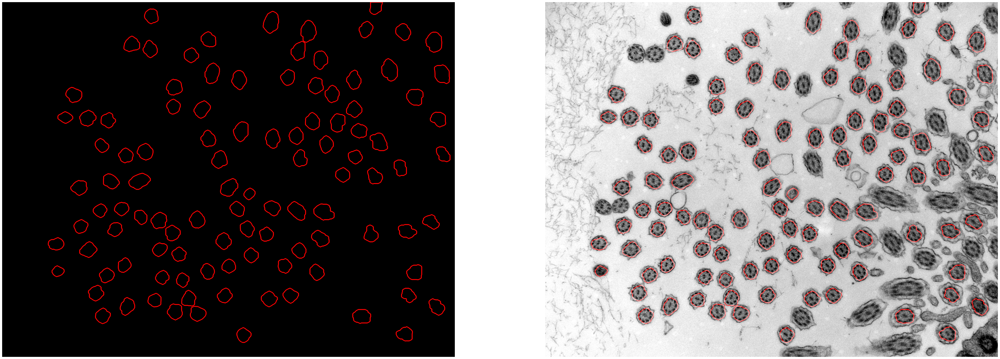

In [6]:
# Example for one image
img_RGB = cv.cvtColor(images[0], cv.COLOR_GRAY2BGR)
img_with_contours = cv.bitwise_or(img_RGB, drawn_contours[0])
iu.plot_images(drawn_contours[0], img_with_contours)

Number of contours found: 24


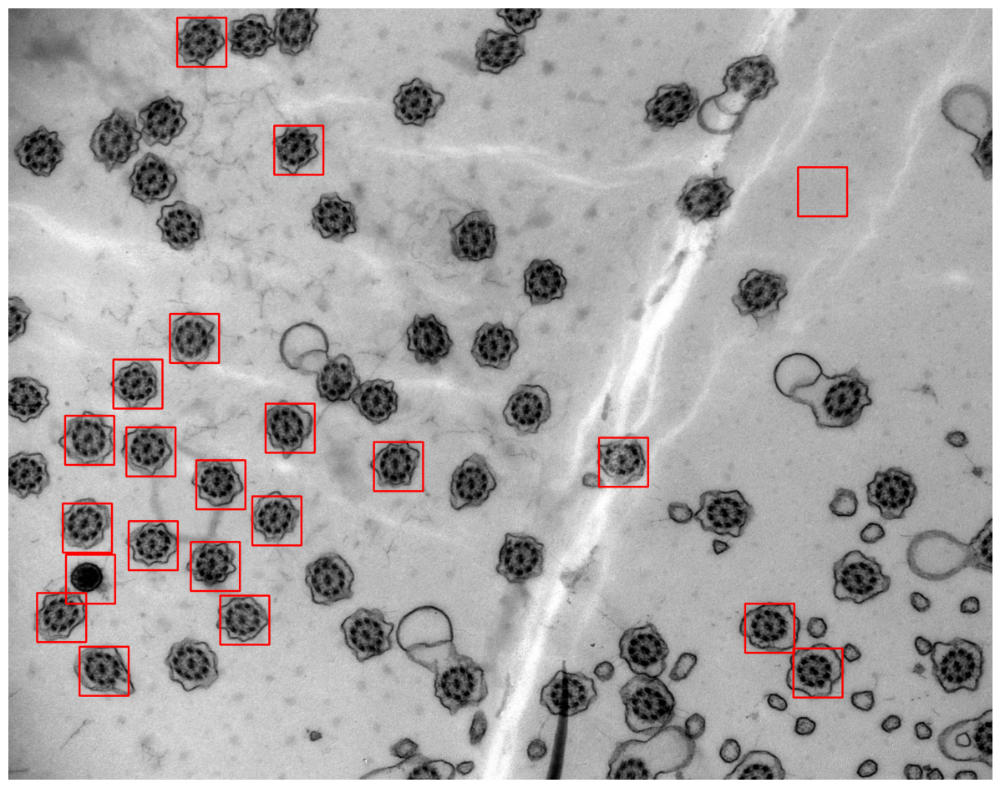

In [7]:
half_side = 85
cells = []
masks = []
imgs_with_boxes = []

for img in images:
    imgs_with_boxes.append(cv.cvtColor(img, cv.COLOR_GRAY2BGR))

for i, filtered_contours in enumerate(contours_in_imgs_filtered):
    i_cells = []
    i_masks = []
    height, width = imgs_with_boxes[i].shape[:2]
    
    for contour in filtered_contours:
        x, y, w, h = cv.boundingRect(contour)
        center_x = x+w//2
        center_y = y+h//2
        x_min = center_x - half_side
        y_min = center_y - half_side
        x_max = center_x + half_side
        y_max = center_y + half_side
        
        if x_min < 0 or y_min < 0 or x_max >= width or y_max >= height:
            continue

        cv.rectangle(
            imgs_with_boxes[i],
            (x_min, y_min),
            (x_max, y_max),
            color=(0, 0, 255),
            thickness=5,
        )
        i_masks.append(opened_imgs[i][y_min:y_max, x_min:x_max])
        i_cells.append(images[i][y_min:y_max, x_min:x_max])
    cells.append(i_cells)
    masks.append(i_masks)

print(f"Number of contours found: {len(contours_in_imgs_filtered[8])}")
iu.plot_images(imgs_with_boxes[8])

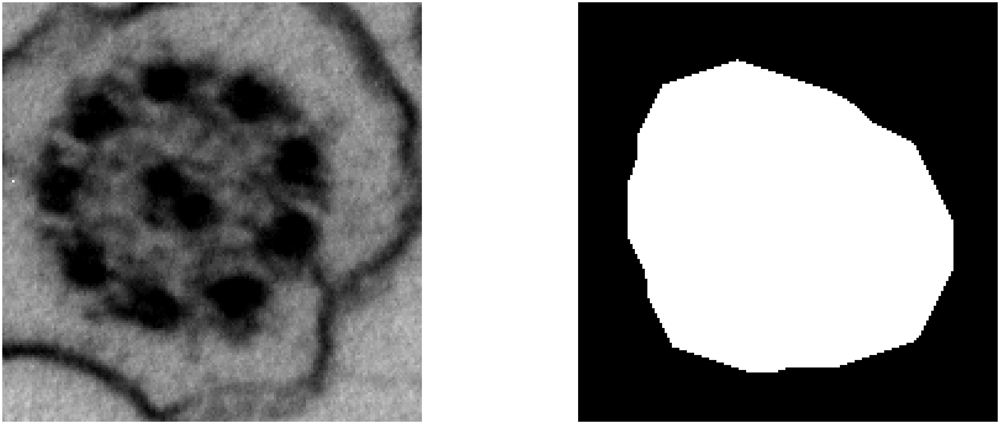

In [ ]:

masks_open = []
for i, mask in enumerate(masks):
    i_masks_open = []
    for j, m in enumerate(mask):
        masked = morph_open(m, ker_erode_SE=True, ker_size_erode=9,
                            iter_erode=8, ker_dilate_SE=True, ker_size_dilate=9, iter_dilate=10)
        i_masks_open.append(masked)
    masks_open.append(i_masks_open)

iu.plot_images(cells[8][0], masks_open[8][0])

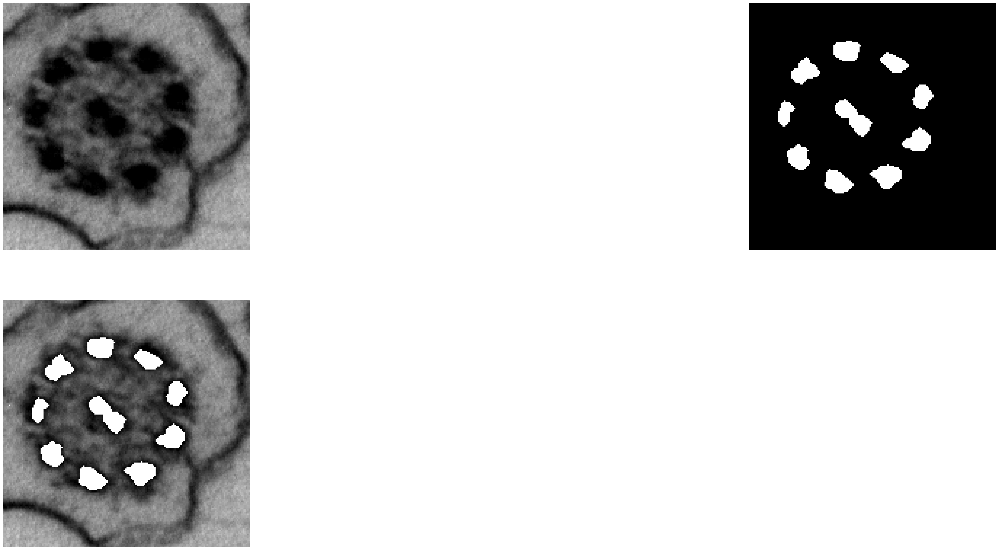

In [ ]:
mask_pts = []

def segment_cell_points(cells, masks_open, mask_pts, image_dir):
    for i, mask in enumerate(masks_open):
        i_mask_pts = []
        for j, m in enumerate(mask):
            recons, mask_rec = reconstruct(cells[i][j], kernel_size=3, iterations=7)
            segmented_mask = cv.bitwise_and(mask_rec, masks_open[i][j])
            opened_mask = morph_open(segmented_mask, ker_erode_SE=False, ker_size_erode=3,
                                    iter_erode=2, ker_dilate_SE=True, ker_size_dilate=3, iter_dilate=2)
            i_mask_pts.append(opened_mask)
        mask_pts.append(i_mask_pts)
        
segment_cell_points(cells, masks_open, mask_pts, image_dir)
matched_img_opened = cv.bitwise_or(mask_pts[8][0], cells[8][0])
iu.plot_images(cells[8][0], mask_pts[8][0], matched_img_opened)

In [ ]:
def save_images_with_boxes_and_masks(cells, masks, mask_pts, imgs_with_boxes, image_dir):
    (image_dir / "boxes").mkdir(parents=True, exist_ok=True)
    (image_dir / "cells").mkdir(parents=True, exist_ok=True)
    (image_dir / "masks").mkdir(parents=True, exist_ok=True)
    (image_dir / "masks_pts").mkdir(parents=True, exist_ok=True)

    for i, img in enumerate(imgs_with_boxes):
        iu.save_image(img, image_dir / "boxes" / f"img_with_boxes_{i}.png")
        for j, cell in enumerate(cells[i]):
            iu.save_image(cell, image_dir / "cells" / f"cell_{i}_{j}.png")
            iu.save_image(masks[i][j], image_dir / "masks" / f"mask_{i}_{j}.png")
            iu.save_image(mask_pts[i][j], image_dir / "masks_pts" / f"mask_pts_{i}_{j}.png")

save_images_with_boxes_and_masks(cells, masks, mask_pts, imgs_with_boxes, image_dir)

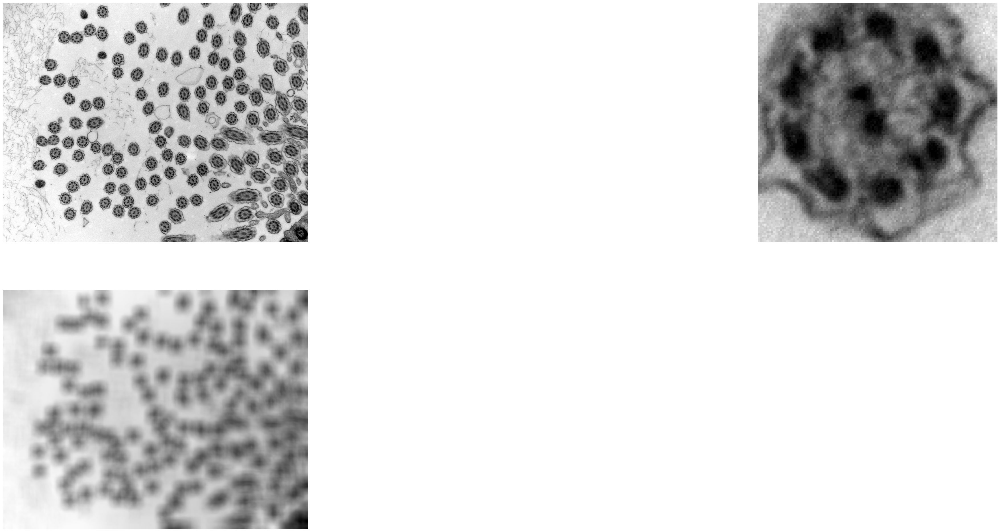

In [ ]:
def conv_with_cell(cells, image):
    kernel_cell = cells[0][22][20:150, 20:150]
    K = kernel_cell.astype(np.float64)
    kernel_norm = K / K.sum()
    conv = cv.filter2D(image, cv.CV_64F, kernel_norm, borderType=cv.BORDER_REFLECT)
    conv_norm = cv.normalize(
        conv, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)
    return iu.to_gray(conv_norm)

conv_norm = conv_with_cell(cells, images[0])
iu.plot_images(images[0], conv_norm)

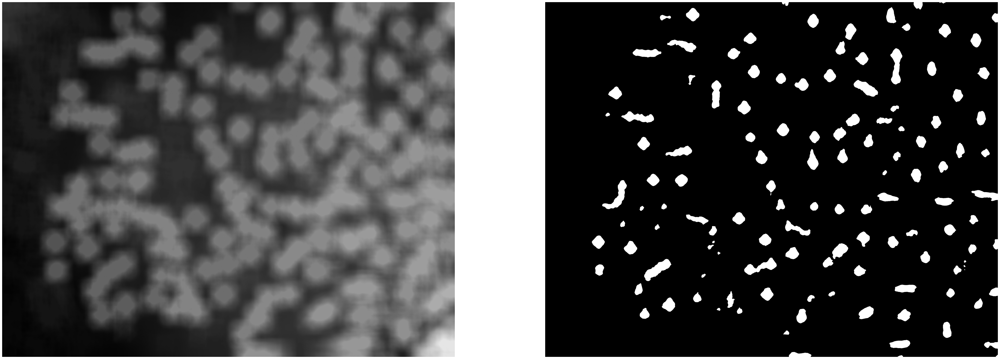

In [12]:
recons, mask = reconstruct(conv_norm, kernel_size=15, iterations=5)
iu.plot_images(recons, mask)


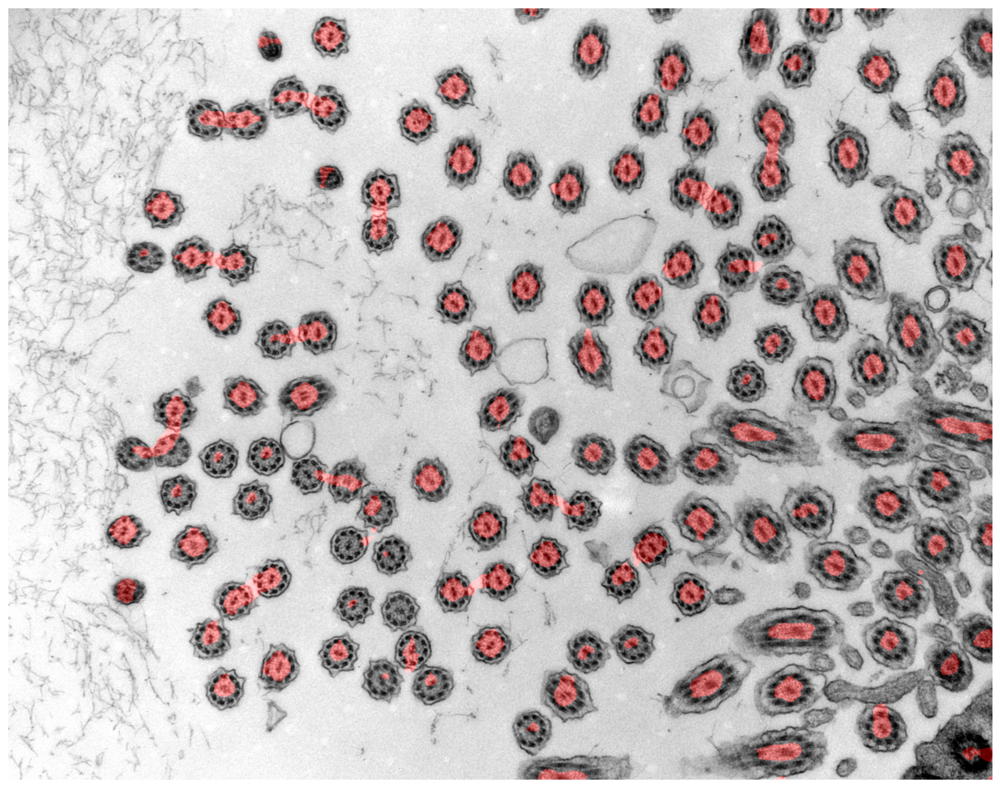

In [13]:
result = cv.cvtColor(images[0], cv.COLOR_GRAY2BGR)
result[:, :, 2] = np.where(
    mask > 10,
    cv.add(result[:, :, 2], 100),
    result[:, :, 2]
)
iu.plot_images(result)